# CALPHAD agent: Single-equilibrium calculations

This demonstration uses an expert assistant, retrieval of TC-Python examples,
and a code-execution proxy. The original task requests share one conversation.

## Notes

> - Thermo-Calc 2024a with FEDEMO, TC-Python and an OpenAI API key are needed to run the calculations. Saved outputs can be inspected without them.
> - Both notebooks use the same agent preparation and `gpt-4o-2024-08-06` at temperature 0.3. New executions may differ.
> - The saved responses and outputs come from one verified execution. Notes identify essential units and assumptions; full conversations and generated scripts are linked below. Private installation paths are redacted.

## Agent setup

Follow the [setup instructions](README.md), then run the cells in order in a fresh kernel.
The reusable [agent setup](agent/agent_setup.py) and [system prompt](agent/prompts/minimal_v5.txt) are shared by both notebooks.


In [1]:
from pathlib import Path
from agent import start_demo

run, agents = start_demo("equilibrium", notebook=Path("single_equilibrium.ipynb").resolve())
run.show_setup()


Model: `gpt-4o-2024-08-06`; temperature: 0.3. [Recorded configuration](outputs/single_equilibrium/configuration.json).

## 1. System Gibbs energy


In [2]:
question_1 = '\nTask:\nMake a Fe-C-Cr single equilibrium calculation with\nTemperature = 2000 K\nX(C) = 0.01\nX(Cr) = 0.1\nCalculate the Gibbs energy of the system.\n\nPlease solve the task, print the result and save it to a json file.\n\n'
print(question_1)



Task:
Make a Fe-C-Cr single equilibrium calculation with
Temperature = 2000 K
X(C) = 0.01
X(Cr) = 0.1
Calculate the Gibbs energy of the system.

Please solve the task, print the result and save it to a json file.




In [3]:
agents.reset()
with run.task("task1", question_1):
    result_1 = agents.proxy_user.initiate_chat(
        agents.assistant, message=question_1, summary_method="reflection_with_llm"
    )
run.show_task("task1", agents.assistant, agents.proxy_user, finish=False)


2026-10-28 21:34:38,196 - autogen.agentchat.contrib.retrieve_user_proxy_agent - INFO - Found 28 chunks.


2026-10-28 21:34:38,218 - autogen.agentchat.contrib.vectordb.chromadb - INFO - No content embedding is provided. Will use the VectorDB's embedding function to generate the content embedding.


task1 : 20 messages; 7 saved files


The code executed successfully, and the Gibbs energy of the Fe-C-Cr system at 2000 K with the specified composition conditions was calculated. The Gibbs energy of the system is approximately \(-130950.87 \, \text{J/mol}\).

The result has been saved to a JSON file named `fe_c_cr_gibbs_energy.json`, which contains the following data:
- Temperature: 2000 K
- Mole fraction of Carbon (C): 0.01
- Mole fraction of Chromium (Cr): 0.1
- Gibbs energy: \(-130950.87 \, \text{J/mol}\)

The approach of summing the Gibbs energies of all stable phases to obtain the total Gibbs energy of the system was successful.

Executions: **5**; unsuccessful executions: **4**. [Full conversation](outputs/single_equilibrium/task1_conversation.json) · [Execution trace](outputs/single_equilibrium/task1_trace.txt). 

Saved data: [fe_c_cr_gibbs_energy.json](outputs/single_equilibrium/artifacts/task1/fe_c_cr_gibbs_energy.json)

**Saved results** (notebook formatting of the agent-generated file).

| Temperature | X(C) | X(Cr) | Gibbs_energy |
| --- | --- | --- | --- |
| 2000 | 0.01 | 0.1 | -130950.86637735169 |

> **Note.** The numerical result is total Gibbs energy, −130950.866377 J, for the default 1 mol system. The agent’s J/mol label is retained in its response.


## 2. M23C6 volume fraction


In [4]:
question_2 = '\nTask:\nMake a Fe-C-Cr single equilibrium calculation with\nTemperature = 700 C\nX(C) = 0.01\nX(Cr) = 0.1\nwhere X(.) means mole fraction.\nObtain the volume fraction of phase M23C6.\n\n\nPlease solve the task, print the result and save it to a json file.\n'
print(question_2)



Task:
Make a Fe-C-Cr single equilibrium calculation with
Temperature = 700 C
X(C) = 0.01
X(Cr) = 0.1
where X(.) means mole fraction.
Obtain the volume fraction of phase M23C6.


Please solve the task, print the result and save it to a json file.



In [5]:
with run.task("task2", question_2):
    agents.proxy_user.send(recipient=agents.assistant, message=question_2)
run.show_task("task2", agents.assistant, agents.proxy_user, finish=False)


task2 : 26 messages; 9 saved files


The code executed successfully, and the volume fraction of the M23C6 phase in the Fe-C-Cr system at 700 °C with the specified composition conditions was calculated. The volume fraction of the M23C6 phase is approximately 0.0419.

The result has been saved to a JSON file named `fe_c_cr_volume_fraction_M23C6.json`, which contains the following data:
- Temperature: 700 °C
- Mole fraction of Carbon (C): 0.01
- Mole fraction of Chromium (Cr): 0.1
- Volume fraction of M23C6: 0.0419

This approach successfully calculated the volume fraction of the specified phase.

Executions: **1**; unsuccessful executions: **0**. [Full conversation](outputs/single_equilibrium/task2_conversation.json) · [Execution trace](outputs/single_equilibrium/task2_trace.txt). 

Saved data: [fe_c_cr_volume_fraction_M23C6.json](outputs/single_equilibrium/artifacts/task2/fe_c_cr_volume_fraction_M23C6.json)

**Saved results** (notebook formatting of the agent-generated file).

| Temperature_C | X(C) | X(Cr) | Volume_fraction_M23C6 |
| --- | --- | --- | --- |
| 700 | 0.01 | 0.1 | 0.04192731946546069 |

## 3. M23C6 composition sweep


In [6]:
question_3 = '\nTask:\n\nLoop over a range of alloy compositions and plot the phase fraction of M23C6\nand handle calculation failures (CalculationException):\n\nTemperature = 700 C\nCr = 5-25 wt-%\nC = 1 mol-%\n\n\nPlease solve the task, print the result and save it to a json file.\n'
print(question_3)



Task:

Loop over a range of alloy compositions and plot the phase fraction of M23C6
and handle calculation failures (CalculationException):

Temperature = 700 C
Cr = 5-25 wt-%
C = 1 mol-%


Please solve the task, print the result and save it to a json file.



task3 : 32 messages; 12 saved files


The code executed successfully, and the phase fraction of M23C6 was calculated for a range of Chromium compositions from 5 to 25 wt-% at 700 °C with 1 mol-% Carbon. The results were plotted and saved to a JSON file.

Key outputs:
- The plot of the volume fraction of M23C6 as a function of Chromium composition was generated and saved as `m23c6_phase_fraction_vs_cr.png`.
- The results, including any calculation failures, were saved to `m23c6_phase_fraction_results.json`.

The code handled exceptions gracefully, allowing the loop to continue even if some calculations failed. This ensured that the results were as complete as possible given the conditions.

Executions: **1**; unsuccessful executions: **0**. [Full conversation](outputs/single_equilibrium/task3_conversation.json) · [Execution trace](outputs/single_equilibrium/task3_trace.txt). 

Saved data: [m23c6_phase_fraction_results.json](outputs/single_equilibrium/artifacts/task3/m23c6_phase_fraction_results.json)

**Saved results** (notebook formatting of the agent-generated file).

| Cr_wt | Volume_fraction_M23C6 |
| --- | --- |
| 5.0 | 0.0 |
| 6.0 | 0.0 |
| 7.0 | 0.0 |
| 8.0 | 0.0 |
| 9.0 | 0.04190310672360002 |
| 10.0 | 0.04195280759774106 |
| 11.0 | 0.041989752207079394 |
| 12.0 | 0.042017263050344054 |
| 13.0 | 0.042037487846821334 |
| 14.0 | 0.04205185040544098 |
| 15.0 | 0.04206131052787283 |
| 16.0 | 0.042066519948765896 |

Showing 12 of 21 records; the linked file contains every record.

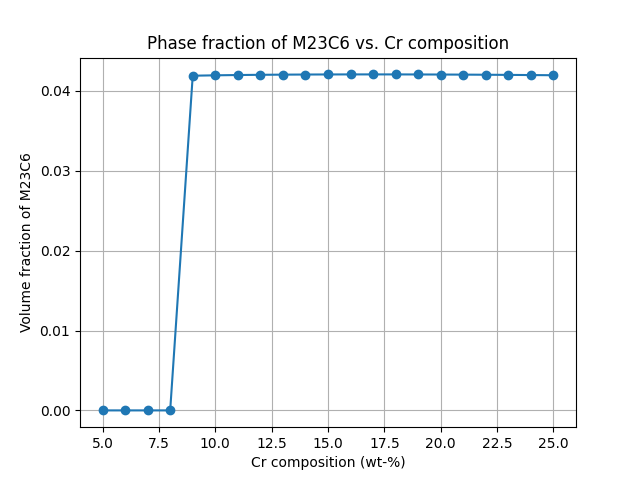

In [7]:
with run.task("task3", question_3):
    agents.proxy_user.send(recipient=agents.assistant, message=question_3)
run.show_task("task3", agents.assistant, agents.proxy_user, finish=False)


> **Note.** The calculation uses chromium mass fraction and carbon mole fraction; the generated conversion comment does not describe the actual setters.


## 4. M7C3 volume-fraction distribution


In [8]:
question_4 = '\nTask:\n\nCalculate the distribution of the M7C3 volume-fraction in the given composition range,\nuse the function numpy.random.multivariate_normal (normal distributed independent samples)\n\nTemperature = 700 C\nCr = 5-25 wt-% (random)\nC = 0 - 1 wt-% (random)\n\n\nPlease solve the task, print the result and save it to a json file.\n'
print(question_4)



Task:

Calculate the distribution of the M7C3 volume-fraction in the given composition range,
use the function numpy.random.multivariate_normal (normal distributed independent samples)

Temperature = 700 C
Cr = 5-25 wt-% (random)
C = 0 - 1 wt-% (random)


Please solve the task, print the result and save it to a json file.



In [9]:
with run.task("task4", question_4):
    agents.proxy_user.send(recipient=agents.assistant, message=question_4)
run.show_task("task4", agents.assistant, agents.proxy_user, finish=True)


task4 : 38 messages; 14 saved files


The code executed successfully, and the distribution of the M7C3 volume fraction was calculated for random compositions of Chromium (Cr) and Carbon (C) within the specified ranges at 700 °C. The results were printed and saved to a JSON file.

Key outputs:
- The results include the random compositions of Cr and C, along with the calculated volume fraction of the M7C3 phase for each composition.
- The results were saved to `m7c3_volume_fraction_distribution.json`.

The code handled the random generation of compositions using a normal distribution and performed equilibrium calculations for each valid composition, storing the results accordingly.

Executions: **1**; unsuccessful executions: **0**. [Full conversation](outputs/single_equilibrium/task4_conversation.json) · [Execution trace](outputs/single_equilibrium/task4_trace.txt). 

Saved data: [m7c3_volume_fraction_distribution.json](outputs/single_equilibrium/artifacts/task4/m7c3_volume_fraction_distribution.json)

**Saved results** (notebook formatting of the agent-generated file).

| Cr_wt | C_wt | Volume_fraction_M7C3 |
| --- | --- | --- |
| 16.279512240737336 | 0.32418962042424615 | 0.0 |
| 14.203220624229132 | 0.9788204295787862 | 0.12059655936138004 |
| 15.076675671314 | 0.8098771380192364 | 0.015425169055452253 |
| 5.622861251746112 | 0.07917439247840469 | 0.009746636698541483 |
| 14.219964402897968 | 0.31380634515373396 | 0.0 |
| 12.30261207376303 | 0.33275413030904033 | 0.0 |
| 15.625308331642103 | 0.4898900709682244 | 0.0 |
| 17.539418571826243 | 0.37020122805510114 | 0.0 |
| 9.77496524154179 | 0.6104522221639512 | 0.07554117667005343 |
| 22.384913364829824 | 0.8407358586644107 | 0.0 |
| 12.432597085165083 | 0.10735353988679525 | 0.0 |
| 14.04374582906609 | 0.3173954551777753 | 0.0 |

Showing 12 of 84 records; the linked file contains every record.

> **Note.** The agent drew 100 normal composition pairs and retained the 84 within the stated ranges. All 84 calculated volume fractions were verified; the full empirical distribution is in the saved JSON.


## Resource use

Measured API tokens and estimated charges for this conversation.


In [10]:
run.show_usage()


| Task | Input tokens | Cached input¹ | Output tokens | Estimated USD² |
| --- | ---: | ---: | ---: | ---: |
| task1 | 158,483 | 104064 | 2,893 | 0.295057 |
| task2 | 88,173 | 83328 | 658 | 0.122853 |
| task3 | 101,313 | 96256 | 908 | 0.142042 |
| task4 | 122,954 | 113792 | 860 | 0.173745 |
| **Total** | **470,923** | **397,440** | **5,319** | **0.733698** |

¹ Cached input is included in input tokens. ² Estimated from returned API usage and [published rates](https://developers.openai.com/api/docs/models/gpt-4o); not an invoice. Includes the original task-1 LLM summary call. Retrieval embeddings and solver execution are local.